<div style="font-family:Georgia, 'Times New Roman', Times, serif; text-align:center; line-height:1.6; color:#111;">
        <div style="border-bottom: 3px double #FF7500; padding-bottom: 15px; width: 80%; margin: 0 auto;">
            <span style="color:#FF7500; font-size:32px; font-weight:normal; font-variant: small-caps;">University of Cyprus</span>
            <br>
            <span style="color:#ccc; font-size:18px; font-style:italic;">Department of Computer Science
            </span>
        </div>
        <br>
        <div style="background-color: #f4f6f9; padding: 15px; border-radius: 4px; width: 60%; margin: 0 auto; border-left: 5px solid #0033cc;">
            <span style="color:#0033cc; font-size:22px; font-weight:bold;">Computer Vision</span>
            <br>
            <span style="font-size:16px;">Instructor: <strong>Dr. Antonis Savva</strong></span>
            <br>
            <span style="font-size:14px; color: #666;">Fall Semester 2026</span>
        </div>
        <br><br>
        <span style="color:#b30000; font-size:48px; font-weight:bold; letter-spacing: -1px;">Assignment 01</span>
        <br>
        <span style="font-size:16px; font-weight:bold; color: #555;">Due Date: October 18<sup>th</sup></span>
        <br><br><br>
        <div style="border-top: 1px solid #ccc; width: 40%; margin: 0 auto; padding-top: 10px;">
            <span style="font-size:20px; font-weight:bold; color: #ccc">Kian Izadpanah</span>
            <br>
            <span style="font-size:16px; font-family: monospace; color: #ccc;">ID: UC1385257</span>
        </div>
</div>

### Setup

First I import the libraries and write some small helper functions:

- `read_image` reads an image from the data folder. If the file is missing, it stops with a clear error.
- `save_image` saves one image in `outputs/` with `cv2.imwrite`.
- `to_rgb` changes BGR to RGB, because OpenCV uses BGR but matplotlib expects RGB.
- `show_grid` shows a list of images in a grid and can also save the figure for the report.

`RESULTS` is a dictionary where I keep all the numbers for the report.

In [1]:
import os, json, math, time
import numpy as np
import cv2
import matplotlib
import matplotlib.pyplot as plt

IMG_DIR = "assignment-1-data"
OUT_DIR = "outputs"
os.makedirs(OUT_DIR, exist_ok=True)

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
                     "axes.titlesize": 10, "font.size": 9})
RESULTS = {}

print("OpenCV", cv2.__version__, "| NumPy", np.__version__, "| Matplotlib", matplotlib.__version__)


def read_image(name, flags=cv2.IMREAD_COLOR):
    path = os.path.join(IMG_DIR, name)
    img = cv2.imread(path, flags)
    if img is None:
        raise FileNotFoundError(f"Could not read '{path}'. Put the course images in '{IMG_DIR}/'.")
    return img


def save_image(name, img):
    cv2.imwrite(os.path.join(OUT_DIR, name), img)


def to_rgb(img):
    return img if img.ndim == 2 else cv2.cvtColor(img, cv2.COLOR_BGR2RGB)


def show_grid(images, titles, ncols, fig_name=None, cell=3.2, cmap="gray", interp="nearest"):
    nrows = math.ceil(len(images) / ncols)
    aspect = max(im.shape[0] / im.shape[1] for im in images)
    fig, axes = plt.subplots(nrows, ncols, figsize=(cell * ncols, nrows * (cell * aspect + 0.35)),
                             squeeze=False)
    for ax in axes.ravel():
        ax.axis("off")
    for ax, img, t in zip(axes.ravel(), images, titles):
        ax.imshow(to_rgb(img), cmap=cmap, interpolation=interp, vmin=0, vmax=255)
        ax.set_title(t)
    fig.tight_layout()
    if fig_name:
        fig.savefig(os.path.join(OUT_DIR, fig_name))
    plt.show()

OpenCV 4.13.0 | NumPy 2.4.3 | Matplotlib 3.10.8


---
# Exercise 1 – Programming exercises

## 1(a) Image resizing with nearest-neighbour interpolation

The new image has size $w \times h$ and the original has size $W \times H$.
For every pixel $(x, y)$ of the new image, I find the matching position in the original image.
I use the centre of each pixel, so both images cover the same area:

$$x_{src} = (x + 0.5)\,\frac{W}{w} - 0.5, \qquad y_{src} = (y + 0.5)\,\frac{H}{h} - 0.5 .$$

These positions are usually not whole numbers. Nearest-neighbour just takes the pixel at the closest
integer position, $\big(\lfloor x_{src} + 0.5 \rfloor,\ \lfloor y_{src} + 0.5 \rfloor\big)$.
I also clip the position to the image, so I never read outside of it.

The function `nn_resize` makes an empty image with the same number of channels as the input
(it works for grayscale and colour), then loops over all the pixels and copies the nearest one.

In [2]:
def nn_resize(image, w, h):
    H, W = image.shape[:2]
    out = np.zeros((h, w) + image.shape[2:], dtype=image.dtype)
    scale_x, scale_y = W / w, H / h

    for y in range(h):
        src_y = (y + 0.5) * scale_y - 0.5
        src_y = math.floor(src_y + 0.5)
        src_y = min(max(src_y, 0), H - 1)
        
        for x in range(w):
            src_x = (x + 0.5) * scale_x - 0.5
            src_x = math.floor(src_x + 0.5)
            src_x = min(max(src_x, 0), W - 1)
            
            out[y, x] = image[src_y, src_x]
    return out

To check my loop version, I also wrote `nn_resize_fast`. It does the same mapping but with NumPy
indexing instead of loops. I only use it to check that the loop version gives exactly the same
image, and to compare the speed.

Then I load `goldfish.jpg` and do a small test: if I make a $2 \times 3$ image twice as big,
every pixel should become a $2 \times 2$ block.

In [3]:
def nn_resize_fast(image, w, h):
    H, W = image.shape[:2]
    ys = np.clip(np.floor((np.arange(h) + 0.5) * H / h), 0, H - 1).astype(int)
    xs = np.clip(np.floor((np.arange(w) + 0.5) * W / w), 0, W - 1).astype(int)
    return image[ys[:, None], xs[None, :]]

tiny = np.arange(6, dtype=np.uint8).reshape(2, 3)
print(nn_resize(tiny, 6, 4))
assert np.array_equal(nn_resize(tiny, 6, 4), np.kron(tiny, np.ones((2, 2), np.uint8)))
print("Test passed: every pixel became a 2x2 block.")

[[0 0 1 1 2 2]
 [0 0 1 1 2 2]
 [3 3 4 4 5 5]
 [3 3 4 4 5 5]]
Test passed: every pixel became a 2x2 block.


In [4]:
goldfish = read_image("goldfish.jpg")
H0, W0 = goldfish.shape[:2]
print(f"goldfish.jpg: {W0} x {H0} pixels, {goldfish.shape[2]} channels")
RESULTS["goldfish_size"] = [W0, H0]

goldfish.jpg: 1250 x 905 pixels, 3 channels


### Downscaling

I make the image 1/2, 1/4 and 1/8 of its size. Each result is saved to disk.
In the figure all of them are drawn at the same display size, so it is easy to see how much detail is lost.
For every size I also check that the loop version and the NumPy version give the same image.

1/2: 625 x 452  (0.21 s with loops)
1/4: 312 x 226  (0.05 s with loops)
1/8: 156 x 113  (0.01 s with loops)


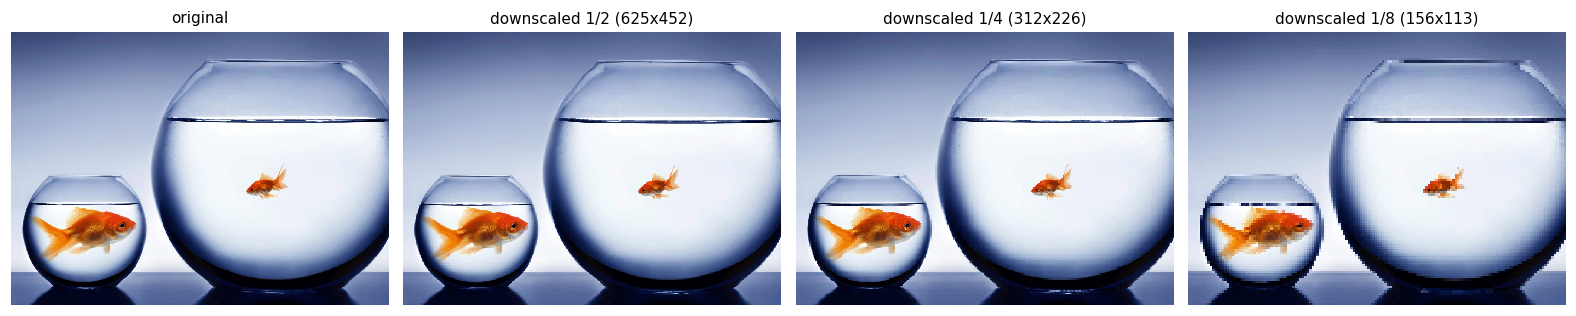

In [5]:
down = {}
for f in [2, 4, 8]:
    w, h = W0 // f, H0 // f
    t0 = time.time()
    down[f] = nn_resize(goldfish, w, h)
    t_loop = time.time() - t0
    assert np.array_equal(down[f], nn_resize_fast(goldfish, w, h))
    save_image(f"1a_down_x{f}.png", down[f])
    print(f"1/{f}: {w} x {h}  ({t_loop:.2f} s with loops)")

show_grid([goldfish] + [down[f] for f in [2, 4, 8]],
          ["original"] + [f"downscaled 1/{f} ({down[f].shape[1]}x{down[f].shape[0]})" for f in [2, 4, 8]],
          ncols=4, fig_name="1a_downscale.png", cell=3.6)